# 10 Model comparison

Every model so far, side by side and scored the same way: the classical models from 07a, LightGBM from 09a, and
seasonal naive as the baseline. Most of the comparison is on the 150-product sample, because that is where every
model was fitted; seasonal naive, ETS and LightGBM also have scores on all 726 products. We test whether the
differences are real, look at bias, and then look for the places where the simple models win.

## Load

In [1]:
import sys, json, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, INTERIM, PROCESSED, TABLES, FIGS, CHECKPOINTS, SEED, CATEGORIES, EVAL_ORIGINS, FIG_STYLE, NAMES, COLORS
from metrics import all_errors, mase_scale, paired_test
from evaluation import METRICS, score, summarise, paired_family

plt.rcParams.update(FIG_STYLE)
written = []
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
saved = pd.read_parquet(PROCESSED / "backtest_forecasts.parquet")
err = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])
scales = err[["item_id", "origin", "mase_scale"]].drop_duplicates()
sample = pd.read_csv(TABLES / "classical_sample_items.csv")
ck = CHECKPOINTS / "items"
parts = [pd.read_parquet(ck / f"{i}.parquet").assign(item_id=i) for i in sample["item_id"]]
classical_fc = pd.concat(parts, ignore_index=True)
totals = {cat: long_df[long_df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = long_df.groupby("date")["sales"].sum()
agg_fc = pd.concat([pd.read_parquet(ck / f"_agg_{k}.parquet").assign(item_id=f"_agg_{k}") for k in totals], ignore_index=True)
print(f"{len(classical_fc):,} classical rows on the sample, {len(saved):,} rows in the full forecast file")

117,600 classical rows on the sample, 1,295,952 rows in the full forecast file


## Every model on the 150 products

In [2]:
reuse = saved[saved["item_id"].isin(sample["item_id"]) & (saved["variant"] == "static")
              & saved["model"].isin(["seasonal_naive", "ets", "lightgbm"])][["item_id", "origin", "date", "model", "forecast"]]
fc = pd.concat([classical_fc[["item_id", "origin", "date", "model", "forecast"]], reuse], ignore_index=True)
fc = fc.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
fc = fc.merge(sample[["item_id", "category"]], on="item_id")
fc.to_parquet(TABLES / "comparison_forecasts.parquet", index=False)
written.append(TABLES / "comparison_forecasts.parquet")

m = score(fc, scales).merge(sample, on="item_id")
m.to_csv(TABLES / "comparison_metrics_item_origin.csv", index=False)
written.append(TABLES / "comparison_metrics_item_origin.csv")

ORDER = ["seasonal_naive", "ets", "hw_add", "hw_mul", "arima", "sarima", "lightgbm"]
ev = m[m["origin"].isin(EVAL_ORIGINS)]
per_item = ev.groupby(["item_id", "category", "break_item", "model"], as_index=False)[METRICS + ["mape_excluded"]].mean()
summary = summarise(per_item, ORDER, CATEGORIES)
summary.to_csv(TABLES / "comparison_metrics_summary.csv", index=False)
written.append(TABLES / "comparison_metrics_summary.csv")
show = summary[summary["category"] == "ALL"].set_index("model").loc[ORDER]
print(show[[f"median_{k}" for k in METRICS]].round(3).to_string())
print("\nmedian MASE by category:")
print(summary.pivot(index="model", columns="category", values="median_mase").loc[ORDER, ["ALL"] + CATEGORIES].round(3).to_string())

                median_rmse  median_mae  median_mape  median_smape  median_wape  median_mase
model                                                                                       
seasonal_naive        6.039       4.720        0.753         0.616        0.581        0.973
ets                   4.498       3.511        0.595         0.471        0.437        0.756
hw_add                4.560       3.560        0.595         0.480        0.442        0.757
hw_mul                4.554       3.586        0.595         0.482        0.439        0.761
arima                 4.822       3.775        0.638         0.484        0.458        0.794
sarima                4.445       3.522        0.603         0.474        0.435        0.755
lightgbm              4.484       3.548        0.574         0.470        0.426        0.747

median MASE by category:
category          ALL  FOODS  HOBBIES  HOUSEHOLD
model                                           
seasonal_naive  0.973  0.931    0.978  

## Are the differences real?

Paired Wilcoxon tests on each product's MASE, Holm-corrected within each group: SARIMA and Holt-Winters against
seasonal naive, and LightGBM against each of the other five.

In [3]:
wide = per_item.pivot(index="item_id", columns="model", values="mase")
tests = pd.DataFrame(paired_family(wide, [("sarima", "seasonal_naive"), ("hw_add", "seasonal_naive")], "H1", seed=SEED)
                     + paired_family(wide, [("lightgbm", x) for x in ["seasonal_naive", "ets", "hw_add", "arima", "sarima"]], "H2", seed=SEED))
tests.to_csv(TABLES / "comparison_tests.csv", index=False)
written.append(TABLES / "comparison_tests.csv")
tests[["hypothesis", "model_a", "model_b", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_holm", "a_better"]].round(4)

,hypothesis,model_a,model_b,n,median_diff,ci_low,ci_high,share_improved,p_holm,a_better
0,H1,sarima,seasonal_naive,150,-0.2234,-0.2370,-0.2000,0.9733,0.0000,True
1,H1,hw_add,seasonal_naive,150,-0.2184,-0.2328,-0.2071,0.9667,0.0000,True
2,H2,lightgbm,seasonal_naive,150,-0.2368,-0.2528,-0.2103,0.9400,0.0000,True
3,H2,lightgbm,ets,150,-0.0078,-0.0120,-0.0027,0.6267,0.0089,True
4,H2,lightgbm,hw_add,150,-0.0083,-0.0140,-0.0020,0.6200,0.0051,True
5,H2,lightgbm,arima,150,-0.0342,-0.0457,-0.0259,0.8200,0.0000,True
6,H2,lightgbm,sarima,150,-0.0070,-0.0137,-0.0015,0.6000,0.0364,True


## The totals

Classical models fitted on each total; seasonal naive, ETS and LightGBM added up from the 726 product forecasts.

In [4]:
agg_rows = []
bottom_up = saved[(saved["variant"] == "static") & saved["model"].isin(["seasonal_naive", "ets", "lightgbm"])].copy()
bottom_up["category"] = bottom_up["item_id"].str.split("_").str[0]
for name, s in totals.items():
    mine = agg_fc[agg_fc["item_id"] == f"_agg_{name}"]
    bu = bottom_up if name == "CA_TOTAL" else bottom_up[bottom_up["category"] == name]
    bu = bu.groupby(["origin", "date", "model"], as_index=False)["forecast"].sum()
    for (origin, model), g in pd.concat([mine[["origin", "date", "model", "forecast"]], bu]).groupby(["origin", "model"]):
        if origin not in EVAL_ORIGINS:
            continue
        act = s.reindex(g["date"]).to_numpy()
        sc = mase_scale(s[s.index <= origin].to_numpy())
        agg_rows.append({"series": name, "origin": origin, "model": model,
                         "how": "fitted on total" if model in ["hw_add", "hw_mul", "arima", "sarima"] else "sum of items",
                         **all_errors(act, g["forecast"], sc)})
agg = pd.DataFrame(agg_rows).groupby(["series", "model", "how"], as_index=False)[METRICS].mean()
agg.to_csv(TABLES / "comparison_totals_metrics.csv", index=False)
written.append(TABLES / "comparison_totals_metrics.csv")
print(agg.pivot(index="model", columns="series", values="mase").loc[ORDER].round(3).to_string())

series          CA_TOTAL  FOODS  HOBBIES  HOUSEHOLD
model                                              
seasonal_naive     0.920  0.913    0.967      1.156
ets                0.769  0.813    0.663      0.897
hw_add             0.791  0.849    0.661      0.907
hw_mul             0.770  0.852    0.670      0.889
arima              0.986  0.888    0.757      1.172
sarima             0.849  1.976    0.674      1.145
lightgbm           0.753  0.737    0.678      0.785


## On all 726 products: LightGBM against ETS

In [5]:
ev726 = err[err["origin"].isin(EVAL_ORIGINS) & (err["variant"] == "static")]
im = ev726.groupby(["item_id", "category", "model"], as_index=False)["mase"].mean()
piv = im.pivot_table(index=["item_id", "category"], columns="model", values="mase").reset_index()
rows = []
for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
    d = piv if cat == "ALL" else piv[piv["category"] == cat]
    rows.append({"comparison": "lightgbm - ets", "category": cat, **paired_test(d["lightgbm"] - d["ets"], seed=SEED)})
lgb_ets = pd.DataFrame(rows)
lgb_ets.to_csv(TABLES / "lgb_vs_ets_test.csv", index=False)
written.append(TABLES / "lgb_vs_ets_test.csv")
print(lgb_ets[["category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "rank_biserial", "p_value"]].round(5).to_string(index=False))

unr = []
for model in ["seasonal_naive", "ets", "lightgbm", "tsb"]:
    d = im[im["model"] == model]
    for cat in ["ALL"] + sorted(d["category"].unique()):
        x = d if cat == "ALL" else d[d["category"] == cat]
        unr.append({"model": model, "category": cat, "n_items": len(x), "median_item_mase": x["mase"].median(),
                    "mean_item_mase": x["mase"].mean()})
unrounded = pd.DataFrame(unr)
unrounded.to_csv(TABLES / "model_mase_unrounded.csv", index=False)
written.append(TABLES / "model_mase_unrounded.csv")

rows = []
for a, b in [("lightgbm", "seasonal_naive"), ("lightgbm", "ets"), ("ets", "seasonal_naive")]:
    for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
        d = piv if cat == "ALL" else piv[piv["category"] == cat]
        rows.append({"model_a": a, "model_b": b, "category": cat, **paired_test(d[a] - d[b], seed=SEED)})
pairwise = pd.DataFrame(rows)
pairwise.to_csv(TABLES / "model_pairwise_tests.csv", index=False)
written.append(TABLES / "model_pairwise_tests.csv")
pairwise[["model_a", "model_b", "category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value"]].round(5)

 category   n  median_diff   ci_low  ci_high  share_improved  rank_biserial  p_value
      ALL 726     -0.00907 -0.01147 -0.00659         0.61570       -0.23627  0.00000
    FOODS 337     -0.01776 -0.02509 -0.01071         0.64985       -0.30957  0.00000
  HOBBIES 106     -0.00488 -0.00974 -0.00199         0.64151       -0.21672  0.05277
HOUSEHOLD 283     -0.00348 -0.00848 -0.00042         0.56537       -0.13472  0.04947


,model_a,model_b,category,n,median_diff,ci_low,ci_high,share_improved,p_value
0,lightgbm,seasonal_naive,ALL,726,-0.22555,-0.23430,-0.21465,0.93526,0.00000
1,lightgbm,seasonal_naive,FOODS,337,-0.20323,-0.21680,-0.19125,0.90208,0.00000
2,lightgbm,seasonal_naive,HOBBIES,106,-0.26335,-0.28499,-0.23729,0.97170,0.00000
3,lightgbm,seasonal_naive,HOUSEHOLD,283,-0.23290,-0.24337,-0.21806,0.96113,0.00000
4,lightgbm,ets,ALL,726,-0.00907,-0.01147,-0.00659,0.61570,0.00000
5,lightgbm,ets,FOODS,337,-0.01776,-0.02509,-0.01071,0.64985,0.00000
6,lightgbm,ets,HOBBIES,106,-0.00488,-0.00974,-0.00199,0.64151,0.05277
7,lightgbm,ets,HOUSEHOLD,283,-0.00348,-0.00848,-0.00042,0.56537,0.04947
8,ets,seasonal_naive,ALL,726,-0.21026,-0.21916,-0.19873,0.96006,0.00000
9,ets,seasonal_naive,FOODS,337,-0.17283,-0.18629,-0.15832,0.92582,0.00000


## Bias: do the models guess too high or too low?

Bias is total forecast over total sales, minus 1. We report it pooled and as the median over products, with a
bootstrap interval for the median.

In [6]:
rng = np.random.default_rng(SEED)
POL_BIAS = [("seasonal_naive", "static"), ("ets", "static"), ("lightgbm", "static"), ("lightgbm", "adaptive")]
saved["category"] = saved["item_id"].str.split("_").str[0]
e = saved[saved["origin"].isin(EVAL_ORIGINS)]
rows = []
for model, variant in POL_BIAS:
    d = e[(e["model"] == model) & (e["variant"] == variant)]
    for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
        x = d if cat == "ALL" else d[d["category"] == cat]
        per = x.groupby("item_id")[["forecast", "actual"]].sum()
        per = per[per["actual"] > 0]
        b = (per["forecast"] / per["actual"] - 1).to_numpy()
        boots = np.median(rng.choice(b, size=(2000, len(b))), axis=1)
        rows.append({"model": model, "variant": variant, "category": cat, "n_items": len(b),
                     "pooled_bias": x["forecast"].sum() / x["actual"].sum() - 1,
                     "median_item_bias": np.median(b), "ci_low": np.quantile(boots, 0.025), "ci_high": np.quantile(boots, 0.975),
                     "share_items_under": np.mean(b < 0)})
bias = pd.DataFrame(rows)
bias.to_csv(TABLES / "forecast_bias.csv", index=False)
written.append(TABLES / "forecast_bias.csv")

item_bias = []
for model, variant in POL_BIAS:
    d = e[(e["model"] == model) & (e["variant"] == variant)].groupby("item_id")[["forecast", "actual"]].sum()
    item_bias.append(pd.DataFrame({"item_id": d.index, "model": model, "variant": variant,
                                   "forecast_units": d["forecast"].to_numpy(), "actual_units": d["actual"].to_numpy(),
                                   "bias": np.where(d["actual"] > 0, d["forecast"] / d["actual"] - 1, np.nan)}))
item_bias = pd.concat(item_bias, ignore_index=True)
item_bias.to_csv(TABLES / "item_bias.csv", index=False)
written.append(TABLES / "item_bias.csv")
bias[bias["category"] == "ALL"].round(4)

,model,variant,category,n_items,pooled_bias,median_item_bias,ci_low,ci_high,share_items_under
0,seasonal_naive,static,ALL,726,-0.0078,0.0014,-0.0052,0.0083,0.4904
4,ets,static,ALL,726,-0.0088,-0.0073,-0.0133,-0.0011,0.5399
8,lightgbm,static,ALL,726,-0.0361,-0.0248,-0.0300,-0.0168,0.6019
12,lightgbm,adaptive,ALL,726,-0.0422,-0.0193,-0.0261,-0.0123,0.5909


## One table for everything

In [7]:
overview = show[["n_items", "median_mase", "median_rmse", "median_mae", "median_smape", "median_wape"]].copy()
mase726 = unrounded[unrounded["category"] == "ALL"].set_index("model")["median_item_mase"]
overview["median_mase_726"] = overview.index.map(mase726)
overview["beats_naive_share"] = [(wide[x] < wide["seasonal_naive"]).mean() if x != "seasonal_naive" else np.nan for x in overview.index]
overview["beats_lightgbm_share"] = [(wide[x] < wide["lightgbm"]).mean() if x != "lightgbm" else np.nan for x in overview.index]
overview = overview.rename(index=NAMES)
overview.to_csv(TABLES / "comparison_overview.csv")
written.append(TABLES / "comparison_overview.csv")
overview.round(3)

,n_items,median_mase,median_rmse,median_mae,median_smape,median_wape,median_mase_726,beats_naive_share,beats_lightgbm_share
model,,,,,,,,,
Seasonal naive,150,0.973,6.039,4.720,0.616,0.581,0.976,NaN,0.060
Damped Holt-Winters (ETS),150,0.756,4.498,3.511,0.471,0.437,0.755,0.967,0.373
Holt-Winters additive,150,0.757,4.560,3.560,0.480,0.442,NaN,0.967,0.380
Holt-Winters multiplicative,150,0.761,4.554,3.586,0.482,0.439,NaN,0.947,0.347
ARIMA,150,0.794,4.822,3.775,0.484,0.458,NaN,0.933,0.180
SARIMA,150,0.755,4.445,3.522,0.474,0.435,NaN,0.973,0.400
LightGBM,150,0.747,4.484,3.548,0.470,0.426,0.744,0.940,NaN


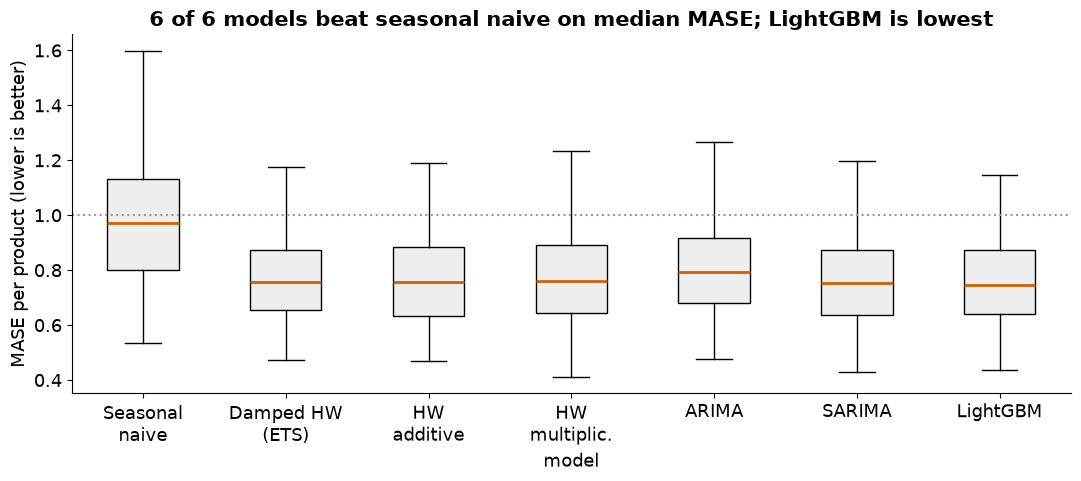

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
data = [wide[x].dropna() for x in ORDER]
ax.boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#EEEEEE"), medianprops=dict(color="#D55E00", lw=2))
SHORT = {"seasonal_naive": "Seasonal\nnaive", "ets": "Damped HW\n(ETS)", "hw_add": "HW\nadditive",
         "hw_mul": "HW\nmultiplic.", "arima": "ARIMA", "sarima": "SARIMA", "lightgbm": "LightGBM"}
ax.set_xticks(range(1, len(ORDER) + 1), [SHORT[x] for x in ORDER])
ax.axhline(1, color="#999999", ls=":")
ax.set_xlabel("model")
ax.set_ylabel("MASE per product (lower is better)")
best = show["median_mase"].idxmin()
n_beat = int((show.drop(index="seasonal_naive")["median_mase"] < show.loc["seasonal_naive", "median_mase"]).sum())
ax.set_title(f"{n_beat} of 6 models beat seasonal naive on median MASE; {NAMES[best]} is lowest")
fig.tight_layout()
fig.savefig(FIGS / "mase_by_model.png")
written.append(FIGS / "mase_by_model.png")
plt.show()

## Where the simple models win

In [9]:
# per product: which model had the lowest MASE?
winner = wide[ORDER].idxmin(axis=1)
print("how often each model is the best of the seven, per product:")
print(winner.value_counts().rename(index=NAMES).to_string())
print(f"\nseasonal naive beats LightGBM on {(wide['seasonal_naive'] < wide['lightgbm']).mean():.0%} of products, "
      f"ETS beats it on {(wide['ets'] < wide['lightgbm']).mean():.0%}, SARIMA on {(wide['sarima'] < wide['lightgbm']).mean():.0%}")
cat_best = summary[summary["category"] != "ALL"].loc[lambda x: x.groupby("category")["median_mase"].idxmin()]
print("\nlowest median MASE per category:", dict(zip(cat_best["category"], cat_best["model"].map(NAMES))))
tot_best = agg.loc[agg.groupby("series")["mase"].idxmin()]
print("lowest MASE per total:", dict(zip(tot_best["series"], tot_best["model"].map(NAMES))))

how often each model is the best of the seven, per product:
LightGBM                       65
Damped Holt-Winters (ETS)      28
SARIMA                         24
Holt-Winters multiplicative    15
Holt-Winters additive          12
ARIMA                           6

seasonal naive beats LightGBM on 6% of products, ETS beats it on 37%, SARIMA on 40%

lowest median MASE per category: {'FOODS': 'SARIMA', 'HOBBIES': 'Damped Holt-Winters (ETS)', 'HOUSEHOLD': 'LightGBM'}
lowest MASE per total: {'CA_TOTAL': 'LightGBM', 'FOODS': 'LightGBM', 'HOBBIES': 'Holt-Winters additive', 'HOUSEHOLD': 'LightGBM'}


## What we found

Every model beats seasonal naive by a wide margin, and the good ones are very close to each other. On the 150
products the median MASE is 0.973 for seasonal naive, 0.794 for ARIMA, and between 0.747 and 0.761 for everything
else: LightGBM 0.747, SARIMA 0.755, ETS 0.756, additive Holt-Winters 0.757, multiplicative 0.761. SARIMA and
additive Holt-Winters beat seasonal naive on about 97% of products (Holm p < 0.001). LightGBM is significantly ahead
of all five others, but against SARIMA, ETS and Holt-Winters the median gain is less than 0.01 MASE, about 1% of the
error. ARIMA, which has no weekly season, is the clear loser among the fitted models.

On all 726 products the picture is the same: LightGBM 0.744, ETS 0.755, seasonal naive 0.976. LightGBM is better
than ETS for 62% of products, and the difference is clear in FOODS but borderline in HOBBIES (p = 0.053) and
HOUSEHOLD (p = 0.0495).

The simple models win more often than the medians suggest. Per product, LightGBM has the lowest MASE of the seven
for only 65 of 150 products; ETS wins 28, SARIMA 24, the two Holt-Winters versions 27 and ARIMA 6. SARIMA beats
LightGBM on 40% of products and ETS on 37%. By category, SARIMA has the lowest median in FOODS (0.741), ETS in
HOBBIES (0.759) and LightGBM in HOUSEHOLD (0.732). On the totals, LightGBM summed over products is best for FOODS,
HOUSEHOLD and California, and additive Holt-Winters fitted on the total wins HOBBIES (0.661). SARIMA fitted directly
on a big total can go badly wrong (FOODS 1.976), which 07b traced to numerical problems with large values.

LightGBM also guesses low. Its total forecast is 3.6% below total sales, and it under-forecasts 60% of products;
ETS and seasonal naive are within 1% in total. That matters for stock: a forecast that is too low runs out unless the
safety stock makes up for it.

So for planning, a well-set-up classical model gives nearly all of LightGBM's accuracy, is easier to explain, and
wins on a large minority of products. LightGBM's edge is real but small.


## What comes next

`11a_uncertainty` asks how honest the uncertainty around these forecasts is, before we turn them into stock decisions.

In [10]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\comparison_forecasts.parquet 1,653 KB
outputs\tables\comparison_metrics_item_origin.csv 1,250 KB
outputs\tables\comparison_metrics_summary.csv 8 KB
outputs\tables\comparison_tests.csv 2 KB
outputs\tables\comparison_totals_metrics.csv 4 KB
outputs\tables\lgb_vs_ets_test.csv 1 KB
outputs\tables\model_mase_unrounded.csv 1 KB
outputs\tables\model_pairwise_tests.csv 2 KB
outputs\tables\forecast_bias.csv 2 KB
outputs\tables\item_bias.csv 211 KB
outputs\tables\comparison_overview.csv 1 KB
outputs\figures\mase_by_model.png 60 KB
